# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** M. Ardhianda Maulana
- **Email:** ardhiim008@gmail.com
- **ID Dicoding:** ardhii_m

- **Pertanyaan 1:** Berapa banyak bike sharing digunakan dan bagaimana perbandingannya pada tahun 2011 dan 2012 ?
- **Pertanyaan 2:** Bagaimana cuaca dan musim dapat menjadi faktor penggunaan bike sharing ?
- **Pertanyaan 3:** Bagaimana penggunaan bike sharing pada hari kerja dan perbedannya pada hari libur ?

## **Import Semua Packages/Library yang Digunakan**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## **Data Wrangling**

### Gathering Data

#### Load df Bike sharing per day

In [2]:
df_day = pd.read_csv('data/day.csv')
df_day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### Load df Bike sharing per hour

In [3]:
df_hour = pd.read_csv('data/hour.csv')
df_hour.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### **Assessing Data**

#### Inspecting df_day dataset

In [4]:
df_day.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [5]:
df_day.describe()


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [6]:
print("Duplicate data: ", df_day.duplicated().sum())
print("Missing data: ")
print(df_day.isnull().sum())

Duplicate data:  0
Missing data: 
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


#### Inspecting df_hour dataset

In [7]:
df_hour.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [8]:
df_hour.describe()


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [9]:
print("Duplicate data: ", df_hour.duplicated().sum())
print("Missing data: ")
print(df_hour.isnull().sum())

Duplicate data:  0
Missing data: 
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


#### Cek Konsistensi Data

In [10]:
if((df_day["casual"] + df_day["registered"] == df_day["cnt"]).all()):
  {
    print("Jumlah casual dan registered sama dengan cnt untuk semua baris dalam df_day.")
  }

if((df_hour["casual"] + df_hour["registered"] == df_hour["cnt"]).all()):
  {
    print("Jumlah casual dan registered sama dengan cnt untuk semua baris dalam df_hour.")
  }

Jumlah casual dan registered sama dengan cnt untuk semua baris dalam df_day.
Jumlah casual dan registered sama dengan cnt untuk semua baris dalam df_hour.


In [11]:
#Check total cnt in df_day and df_hour
print("Total cnt in df_day:", df_day['cnt'].sum())
print("Total cnt in df_hour:", df_hour['cnt'].sum())

Total cnt in df_day: 3292679
Total cnt in df_hour: 3292679


#### Cek Outlier pada Data

In [12]:
def check_outliers(df, column):
    Q1 = np.percentile(df[column], 25)
    Q3 = np.percentile(df[column], 75)
    IQR = Q3 - Q1
    cut_off = IQR * 1.5
    minimum = Q1 - cut_off
    maximum = Q3 + cut_off
    outliers = df[(df[column] < minimum) | (df[column] > maximum)]
    return print(f"{column}: {len(outliers)}")

In [13]:
#Menghitung jumlah outlier pada kolom numerik pada df_day
print("Outlier pada df_day:")
for column in df_day.columns:
    if column in ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']:
        check_outliers(df_day, column)

Outlier pada df_day:
temp: 0
atemp: 0
hum: 2
windspeed: 13
casual: 44
registered: 0
cnt: 0


In [14]:
#Menghitung jumlah outlier pada kolom numerik pada df_hour
print("Outlier pada df_hour:")
for column in df_hour.columns:
    if column in ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']:
        check_outliers(df_hour, column)

Outlier pada df_hour:
temp: 0
atemp: 0
hum: 22
windspeed: 342
casual: 1192
registered: 680
cnt: 505


**Steps to Take:**
- Mengubah tipe data kolom dteday menjadi tipe data datetime.
- Mengubah tipe data kolom season, mnth, hr, holiday, weekday, workingday, weathersit menjadi tipe data kategorikal. 
- Drop kolom instant, holiday, dan atemp.
- Decode Value pada kolom season, mnth, holiday, weekday, workingday, weathersit.
- Mengubah nama masing-masing kolom pada data sehingga lebih mudah dibaca.
- Penanganan Outlier hum dan windspeed pada kedua dataset.

**Insight:**
- Tidak ada missing values dan data yang duplikat, sehingga tidak perlu melakukan imputasi data.
- data season, holiday, workingday, weathersit tidak berupa tipe data kategorikal, melainkan tipe data integer. Sehingga tipe data tersebut perlu diubah.
- Jumlah user casual dan user registered sama dengan total user (cnt), sehingga data masing-masing dataframe konsisten.
- Terdapat Outlier pada kolom data hum, windspeed, casual, registered, dan cnt. Namun data pada kolom user (casual, registered, cnt) sangat penting dan dapat merusak data jika ditangani.

### Cleaning Data

#### Drop kolom yang tidak digunakan

In [15]:
df_day.drop(['instant'], axis=1, inplace=True)
df_hour.drop(['instant'], axis=1, inplace=True)
df_day.drop(['holiday'], axis=1, inplace=True)
df_hour.drop(['holiday'], axis=1, inplace=True)
df_day.drop(['atemp'], axis=1, inplace=True)
df_hour.drop(['atemp'], axis=1, inplace=True)

#### Mengubah tipe data kolom yang salah

In [16]:
df_day['dteday'] = pd.to_datetime(df_day['dteday'])
df_hour['dteday'] = pd.to_datetime(df_hour['dteday'])

categorical_cols = ['season', 'yr', 'mnth', 'weekday', 'workingday', 'weathersit']

for column in categorical_cols:
    df_day[column] = df_day[column].astype('category')
    df_hour[column] = df_hour[column].astype('category')

#### Mengubah value kolom kategorikal

In [17]:
# Fungsi Mapping data kategorikal
def categorical_mapping(df, column, mapping_dict):
    df[column] = df[column].map(mapping_dict)

In [18]:
# Mengubah kategori data day
categorical_mapping(df_day, 'season', {1:'Spring', 2:'Summer', 3:'Fall', 4:'Winter'})
categorical_mapping(df_day, 'yr', {0:'2011', 1:'2012'})
categorical_mapping(df_day, 'mnth', {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'Jun', 7:'Jul', 8:'Aug', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'})
categorical_mapping(df_day, 'weekday', {0:'Sun', 1:'Mon', 2:'Tue', 3:'Wed', 4:'Thu', 5:'Fri', 6:'Sat'})
categorical_mapping(df_day, 'weathersit', {1:'Clear', 2:'Mist', 3:'Light Snow/Rain', 4:'Heavy Rain/Snow'})
categorical_mapping(df_day, 'workingday', {0:'No', 1:'Yes'})

# Mengubah kategori data hour
categorical_mapping(df_hour, 'season', {1:'Spring', 2:'Summer', 3:'Fall', 4:'Winter'})
categorical_mapping(df_hour, 'yr', {0:'2011', 1:'2012'})
categorical_mapping(df_hour, 'mnth', {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'Jun', 7:'Jul', 8:'Aug', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'})
categorical_mapping(df_hour, 'weekday', {0:'Sun', 1:'Mon', 2:'Tue', 3:'Wed', 4:'Thu', 5:'Fri', 6:'Sat'})
categorical_mapping(df_hour, 'weathersit', {1:'Clear', 2:'Mist', 3:'Light Snow/Rain', 4:'Heavy Rain/Snow'})
categorical_mapping(df_hour, 'workingday', {0:'No', 1:'Yes'})

#### Rename nama kolom sehingga lebih mudah dibaca

In [19]:
df_day.rename(columns={'dteday': 'date', 'yr': 'year', 'mnth': 'month', 'weathersit': 'weather', 'hum': 'humidity', 'cnt': 'total_user_count'}, inplace=True)
df_hour.rename(columns={'dteday': 'date', 'yr': 'year', 'mnth': 'month', 'hr': 'hour', 'weathersit': 'weather', 'hum': 'humidity', 'cnt': 'total_user_count'}, inplace=True)

#### Preview Dataset yang dibersihkan

In [20]:
df_day.head()

,date,season,year,month,weekday,workingday,weather,temp,humidity,windspeed,casual,registered,total_user_count
0,2011-01-01,Spring,2011,Jan,Sat,No,Mist,0.344167,0.805833,0.160446,331,654,985
1,2011-01-02,Spring,2011,Jan,Sun,No,Mist,0.363478,0.696087,0.248539,131,670,801
2,2011-01-03,Spring,2011,Jan,Mon,Yes,Clear,0.196364,0.437273,0.248309,120,1229,1349
3,2011-01-04,Spring,2011,Jan,Tue,Yes,Clear,0.200000,0.590435,0.160296,108,1454,1562
4,2011-01-05,Spring,2011,Jan,Wed,Yes,Clear,0.226957,0.436957,0.186900,82,1518,1600


In [21]:
df_hour.head()

,date,season,year,month,hour,weekday,workingday,weather,temp,humidity,windspeed,casual,registered,total_user_count
0,2011-01-01,Spring,2011,Jan,0,Sat,No,Clear,0.24,0.81,0.0,3,13,16
1,2011-01-01,Spring,2011,Jan,1,Sat,No,Clear,0.22,0.80,0.0,8,32,40
2,2011-01-01,Spring,2011,Jan,2,Sat,No,Clear,0.22,0.80,0.0,5,27,32
3,2011-01-01,Spring,2011,Jan,3,Sat,No,Clear,0.24,0.75,0.0,3,10,13
4,2011-01-01,Spring,2011,Jan,4,Sat,No,Clear,0.24,0.75,0.0,0,1,1


**Insight:**
- Dataset yang diberikan cukup bersih, sehingga tidak banyak hal yang perlu diolah.
- Data workingday dan holiday memiliki value yang berlawanan, sehingga hanya memerlukan salah satu kolom tersebut.


## **Exploratory Data Analysis (EDA)**

### Eksplorasi Dataset yang Dibersihkan

In [22]:
df_day.describe(include='all')

,date,season,year,month,weekday,workingday,weather,temp,humidity,windspeed,casual,registered,total_user_count
count,731,731,731,731,731,731,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
unique,NaN,4,2,12,7,2,3,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Fall,2012,Jan,Sun,Yes,Clear,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,188,366,62,105,500,463,NaN,NaN,NaN,NaN,NaN,NaN
mean,2012-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,0.495385,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,2011-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,0.059130,0.000000,0.022392,2.000000,20.000000,22.000000
25%,2011-07-02 12:00:00,NaN,NaN,NaN,NaN,NaN,NaN,0.337083,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,2012-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,0.498333,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,2012-07-01 12:00:00,NaN,NaN,NaN,NaN,NaN,NaN,0.655417,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,2012-12-31 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,0.861667,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [23]:
df_hour.describe(include='all')

,date,season,year,month,hour,weekday,workingday,weather,temp,humidity,windspeed,casual,registered,total_user_count
count,17379,17379,17379,17379,17379.000000,17379,17379,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
unique,NaN,4,2,12,NaN,7,2,4,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Fall,2012,Jul,NaN,Sat,Yes,Clear,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,4496,8734,1488,NaN,2512,11865,11413,NaN,NaN,NaN,NaN,NaN,NaN
mean,2012-01-02 04:08:34.552045568,NaN,NaN,NaN,11.546752,NaN,NaN,NaN,0.496987,0.627229,0.190098,35.676218,153.786869,189.463088
min,2011-01-01 00:00:00,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,0.020000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2011-07-04 00:00:00,NaN,NaN,NaN,6.000000,NaN,NaN,NaN,0.340000,0.480000,0.104500,4.000000,34.000000,40.000000
50%,2012-01-02 00:00:00,NaN,NaN,NaN,12.000000,NaN,NaN,NaN,0.500000,0.630000,0.194000,17.000000,115.000000,142.000000
75%,2012-07-02 00:00:00,NaN,NaN,NaN,18.000000,NaN,NaN,NaN,0.660000,0.780000,0.253700,48.000000,220.000000,281.000000
max,2012-12-31 00:00:00,NaN,NaN,NaN,23.000000,NaN,NaN,NaN,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


### Eksplorasi Jumlah User Bike Share

In [24]:
total_users= df_day['total_user_count'].sum()
total_users


np.int64(3292679)

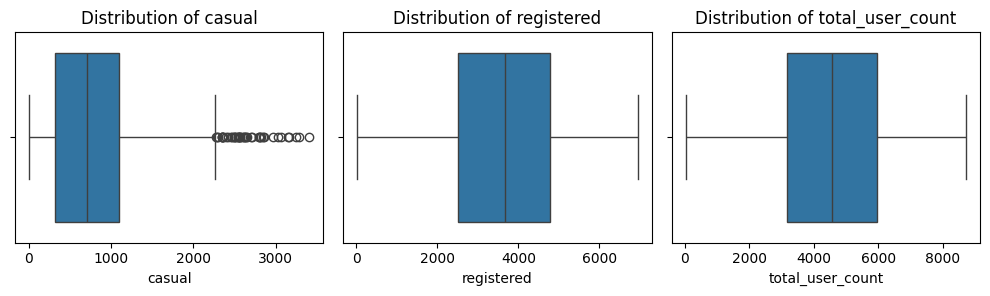

In [25]:
user_cols = ['casual', 'registered', 'total_user_count']

plt.figure(figsize=(10, 8))
for i, col in enumerate(user_cols):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(x=df_day[col])
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()


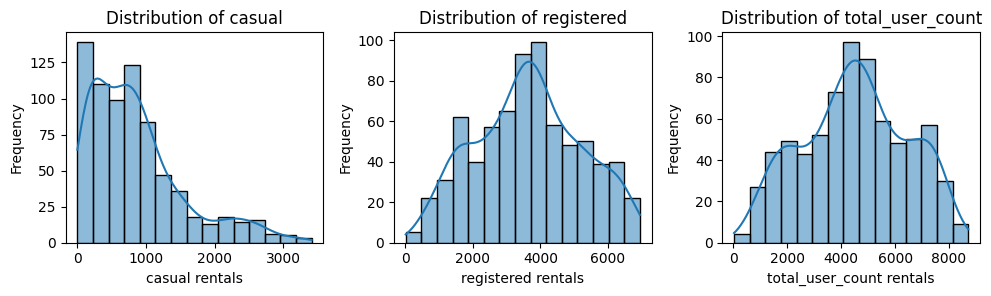

In [26]:
plt.figure(figsize=(10, 8))
for i, col in enumerate(user_cols):
    plt.subplot(3, 3, i + 1)
    sns.histplot(df_day[col], bins=15, kde=True)
    plt.xlabel(f'{col} rentals')
    plt.ylabel('Frequency')
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

**Insight** :
- Data User casual memiliki distribusi *Right-skewed*, dengan penggunaan pada umumnya relatif rendah.
- User registered memiliki distribusi normal dengan penggunaan bike sharing yang sering dilakukan pada setiap harinya.

### Eksplorasi User Harian

#### Rata-rata User Harian

In [27]:
avg_users = df_day[['casual', 'registered', 'total_user_count']].mean()
avg_users


casual               848.176471
registered          3656.172367
total_user_count    4504.348837
dtype: float64

#### Rata-rata User per Minggu

In [28]:
avg_by_weekday = (df_day.groupby("weekday", observed=True)[["casual", "registered"]].mean().reset_index())
avg_by_weekday

,weekday,casual,registered
0,Sun,1338.295238,2890.533333
1,Mon,674.133333,3663.990476
2,Tue,556.182692,3954.480769
3,Wed,551.144231,3997.394231
4,Thu,590.961538,4076.298077
5,Fri,752.288462,3938.000000
6,Sat,1465.257143,3085.285714


In [29]:
weekly_users = df_day.set_index('date').resample('W')['total_user_count'].mean().reset_index()
weekly_users

,date,total_user_count
0,2011-01-02,893.000000
1,2011-01-09,1344.000000
2,2011-01-16,1289.285714
3,2011-01-23,1252.857143
4,2011-01-30,1099.857143
...,...,...
101,2012-12-09,5394.571429
102,2012-12-16,5138.000000
103,2012-12-23,3813.714286
104,2012-12-30,1531.428571


#### Rata-rata User Bike per Bulan dan Tahun

In [30]:
monthly_users = (df_day.set_index("date").resample("ME")["casual", "registered", "total_user_count"].mean())
monthly_users


,casual,registered,total_user_count
date,,,
2011-01-31,99.129032,1132.774194,1231.903226
2011-02-28,222.928571,1499.035714,1721.964286
2011-03-31,413.741935,1652.225806,2065.967742
2011-04-30,744.866667,2417.466667,3162.333333
2011-05-31,1001.612903,3379.709677,4381.322581
2011-06-30,1020.400000,3763.333333,4783.733333
2011-07-31,1175.870968,3383.516129,4559.387097
2011-08-31,930.387097,3479.000000,4409.387097
2011-09-30,884.833333,3362.433333,4247.266667


In [31]:
monthly_growth = df_day.groupby(['year', 'month'], observed=True)['registered'].mean().reset_index()
monthly_growth

,year,month,registered
0,2011,Jan,1132.774194
1,2011,Feb,1499.035714
2,2011,Mar,1652.225806
3,2011,Apr,2417.466667
4,2011,May,3379.709677
5,2011,Jun,3763.333333
6,2011,Jul,3383.516129
7,2011,Aug,3479.000000
8,2011,Sep,3362.433333
9,2011,Oct,3170.612903


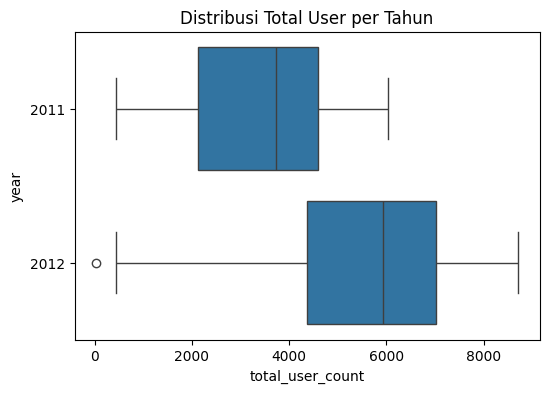

In [32]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df_day['year'], x=df_day['total_user_count'])
plt.title(f'Distribusi Total User per Tahun')
plt.show()

In [33]:
yearly_registered = (
    df_day
    .groupby(df_day["date"].dt.year)["registered"]
    .sum()
    .reset_index(name="total_registered")
)

yearly_registered.rename(columns={"date": "year"}, inplace=True)

yearly_registered["growth_rate"] = (
    yearly_registered["total_registered"]
    .pct_change() * 100
)

print(yearly_registered)

   year  total_registered  growth_rate
0  2011            995851          NaN
1  2012           1676811    68.379707


**Insight** :
- Rata-rata penggunaan bike share setiap harinya sebesar 4504, dengan 3656 User yang terdaftar menggunakan layanan.

- Jumlah user yang terdaftar meningkat pada tahun kedua (2012) meningkat sebesar 68%.

### Eksplorasi Bike Share terhadap Cuaca dan Musim

In [34]:
df_day.groupby(('weather'), observed=True)['total_user_count'].mean().reset_index().sort_values(by='total_user_count', ascending=False)

,weather,total_user_count
0,Clear,4876.786177
1,Mist,4035.862348
2,Light Snow/Rain,1803.285714


In [35]:
avg_season = df_day.groupby(('season'), observed=True)['total_user_count'].mean().reset_index().sort_values(by='total_user_count', ascending=False)
avg_season

,season,total_user_count
2,Fall,5644.303191
1,Summer,4992.331522
3,Winter,4728.162921
0,Spring,2604.132597


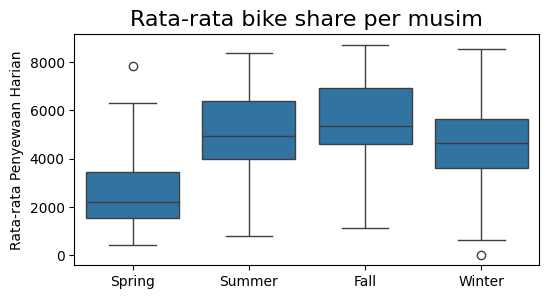

In [36]:
plt.figure(figsize=(6,3))
sns.boxplot(
    x=df_day["season"],
    y=df_day["total_user_count"],
)

plt.title("Rata-rata bike share per musim", fontsize=16)
plt.xlabel("")
plt.ylabel("Rata-rata Penyewaan Harian")
plt.show()

In [37]:
df_day.groupby(('season'), observed=True)['total_user_count'].mean().reset_index().sort_values(by='total_user_count', ascending=True)

,season,total_user_count
0,Spring,2604.132597
3,Winter,4728.162921
1,Summer,4992.331522
2,Fall,5644.303191


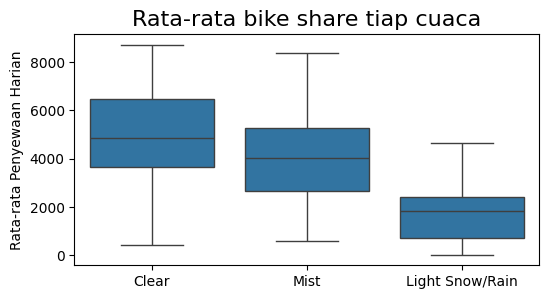

In [38]:
plt.figure(figsize=(6,3))
sns.boxplot(
    x=df_day["weather"],
    y=df_day["total_user_count"],
)

plt.title("Rata-rata bike share tiap cuaca", fontsize=16)
plt.xlabel("")
plt.ylabel("Rata-rata Penyewaan Harian")
plt.show()

**Insight** :
- Penggunaan Bike sharing sering digunakan saat cuaca normal dan menurun secara signifikan saat cuaca hujan.
- Rata-rata penggunaan bike sharing sangat tinggi saat musim panas dan musim gugur, dan sangat sedikit saat musim semi sehingga memiliki rata-rata terendah.

### Eksplorasi Rental Bike Share Terhadap Waktu dan Hari Kerja

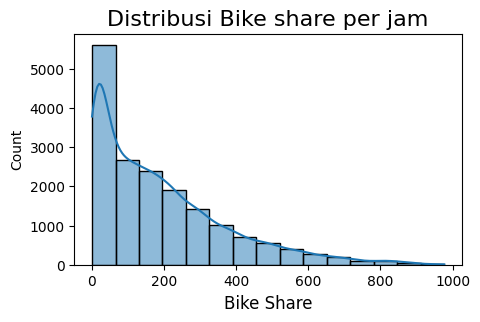

In [39]:
plt.figure(figsize=(5,3))
sns.histplot(
    data=df_hour,
    x="total_user_count",
    bins=15,
    kde=True
)

plt.title("Distribusi Bike share per jam", fontsize=16)
plt.xlabel("Bike Share", fontsize=12)
plt.show()

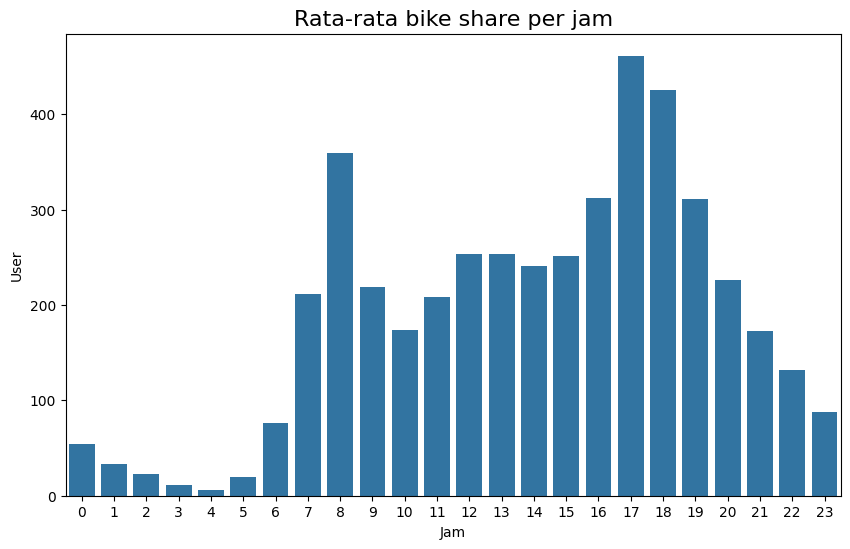

In [40]:
hourly_users = (df_hour.groupby("hour", observed=True)[user_cols].mean().reset_index())

plt.figure(figsize=(10, 6))
sns.barplot(
  x=hourly_users["hour"],
  y=hourly_users["total_user_count"]
)
plt.title("Rata-rata bike share per jam", fontsize=16)
plt.xlabel("Jam")
plt.ylabel("User")
plt.show()

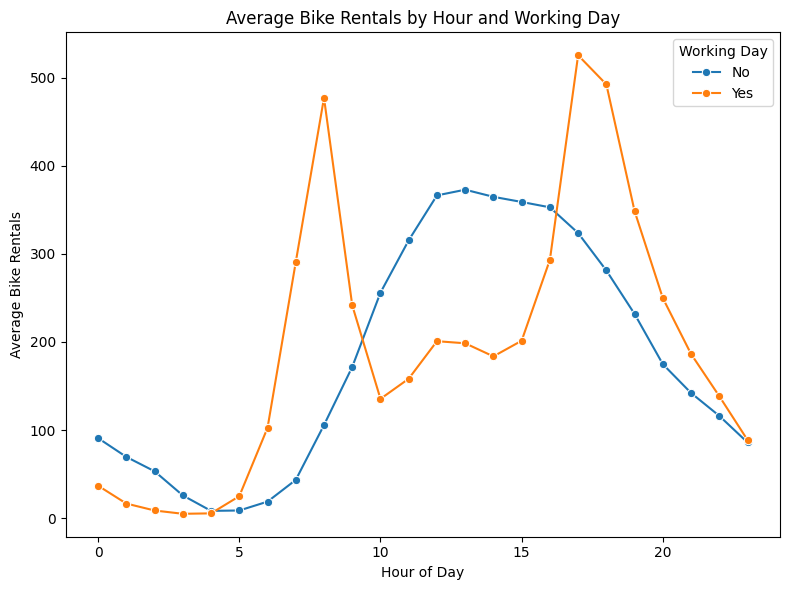

In [41]:
hourly_workday = (df_hour.groupby(['hour', 'workingday'], observed=True)['total_user_count'].mean().reset_index())

plt.figure(figsize=(8, 6))
sns.lineplot(
  data=hourly_workday,
  x="hour",
  y="total_user_count",
  hue="workingday",
  marker="o",
)

plt.title("Average Bike Rentals by Hour and Working Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Bike Rentals")
plt.legend(title="Working Day")
plt.tight_layout()
plt.show()

In [42]:
workdays = (df_day.groupby('workingday', observed=True)[user_cols].mean().reset_index())
workdays

,workingday,casual,registered,total_user_count
0,No,1371.134199,2959.034632,4330.168831
1,Yes,606.570000,3978.250000,4584.820000


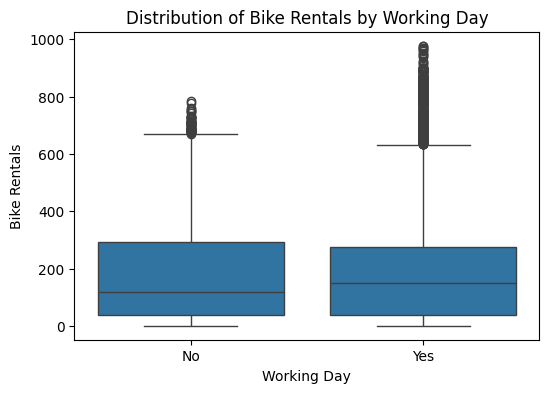

In [43]:
plt.figure(figsize=(6,4))

sns.boxplot(
    data=df_hour,
    x="workingday",
    y="total_user_count"
)

plt.title("Distribution of Bike Rentals by Working Day")
plt.xlabel("Working Day")
plt.ylabel("Bike Rentals")

plt.xticks([0,1], ["No","Yes"])

plt.show()

**Insight:**
- Penggunaan bike share meningkat tajam pada pukul 8 dan memuncak pada pukul 17 hingga 18 sore.
- Penggunaan yang tinggi sangat jarang terjadi, sehingga distribusi yang didapatkan berupa *right-skewed*.
- Tidak ada peningkatan tajam pada penggunaan bike sharing saat hari libur dari pagi hingga sore, mengindikasikan penggunaan yang sangat luang.

## **Visualization & Explanatory Analysis**

### Pertanyaan 1: Berapa banyak bike sharing digunakan dan bagaimana perbandingannya pada tahun 2011 dan 2012 ?

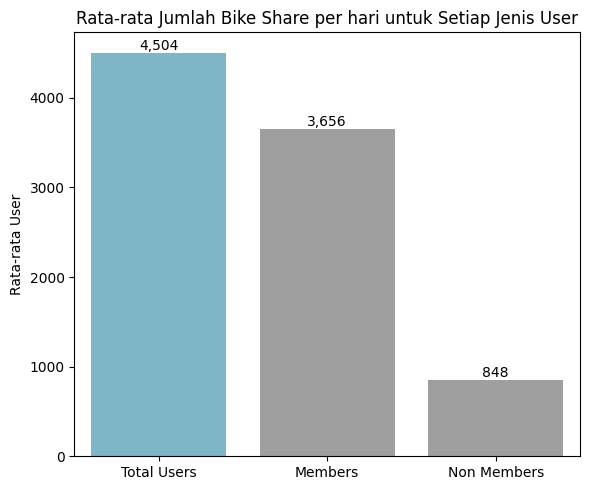

In [44]:
avg_users = df_day[['casual', 'registered', 'total_user_count']].mean().reset_index()
avg_users.columns = ['user_type', 'average_count']
avg_users["user_type"] = avg_users["user_type"].replace({
    "casual": "Non Members",
    "registered": "Members",
    "total_user_count": "Total Users"
})

plt.figure(figsize=(6,5))
colors_ = ["#72BCD4", "#9F9F9F", "#9F9F9F"]
ax = sns.barplot(
    data=avg_users.sort_values(by='average_count', ascending=False),
    x="user_type",
    y="average_count",
    hue="user_type",
    palette=colors_,
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="{:,.0f}",
    )

plt.title("Rata-rata Jumlah Bike Share per hari untuk Setiap Jenis User")
plt.xlabel("")
plt.xticks(rotation=0)
plt.ylabel("Rata-rata User")
plt.tight_layout()
plt.show()

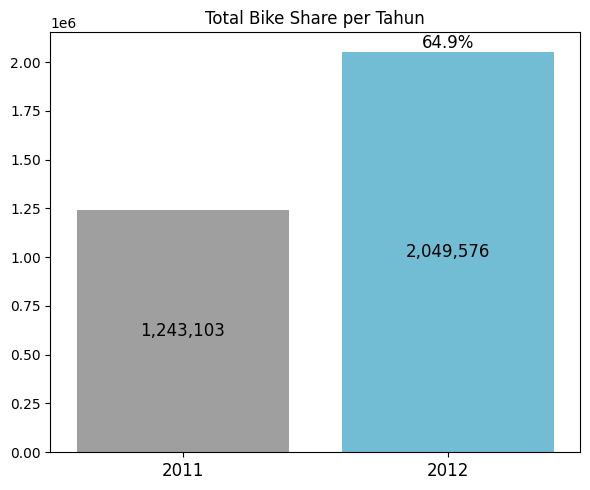

In [45]:
yearly_usage = (df_day.groupby(df_day["date"].dt.year)["total_user_count"].sum().reset_index())

yearly_usage["growth_rate"] = (yearly_usage["total_user_count"].pct_change() * 100)

plt.figure(figsize=(6,5))
ax = sns.barplot(
  x=yearly_usage["date"],
  y=yearly_usage["total_user_count"],
)

colors = [
    "#72BCD4" if value == yearly_usage["total_user_count"].max() else "#9F9F9F"
    for value in yearly_usage["total_user_count"]
]
for patch, color in zip(ax.patches, colors):
    patch.set_facecolor(color)

for container in ax.containers:
    ax.bar_label(container, labels=yearly_usage["total_user_count"].apply(lambda x: f"{x:,.0f}"), label_type='center', color='black', fontsize=12)
    ax.bar_label(container, labels=yearly_usage["growth_rate"].apply(lambda x: f"{x:.1f}%" if pd.notna(x) else ""), label_type='edge', fontsize=12)

plt.title("Total Bike Share per Tahun")
plt.xticks(rotation=0, fontsize=12)
plt.xlabel("")
plt.ylabel("")

plt.tight_layout()
plt.show()

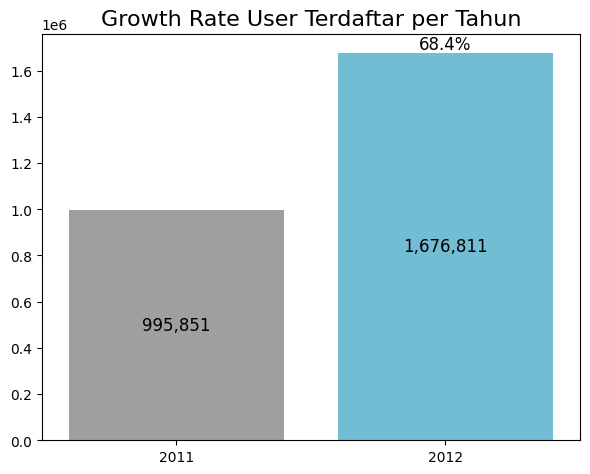

In [46]:
yearly_registered = (df_day.groupby(df_day["date"].dt.year)["registered"].sum().reset_index())

yearly_registered["growth_rate"] = (
    yearly_registered["registered"]
    .pct_change() * 100
)

plt.figure(figsize=(6,5))
ax = sns.barplot(
    x=yearly_registered["date"],
    y=yearly_registered["registered"],
)

colors = [
    "#72BCD4" if value == yearly_registered["registered"].max() else "#9F9F9F"
    for value in yearly_registered["registered"]
]

for patch, color in zip(ax.patches, colors):
    patch.set_facecolor(color)

for container in ax.containers:
    ax.bar_label(container, labels=yearly_registered["registered"].apply(lambda x: f"{x:,.0f}"), label_type='center', color='black', fontsize=12)
    ax.bar_label(container, labels=yearly_registered["growth_rate"].apply(lambda x: f"{x:.1f}%" if pd.notna(x) else ""), label_type='edge', fontsize=12)

plt.title("Growth Rate User Terdaftar per Tahun", fontsize=16)
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana cuaca dan musim dapat menjadi faktor penggunaan bike sharing ?

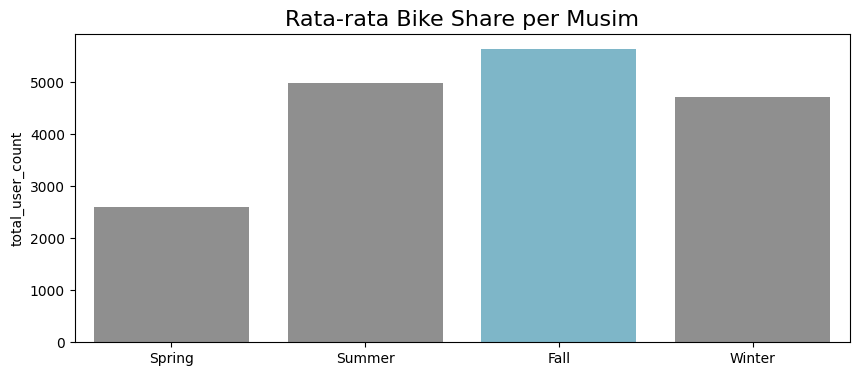

In [47]:
plt.figure(figsize=(10, 4))
sns.barplot(
  data=df_day,
  x="season",
  y="total_user_count",
  hue="season",
  palette = ["#8f8f8f", "#8f8f8f", "#72BCD4", "#8f8f8f"],
  errorbar=None
)

plt.title("Rata-rata Bike Share per Musim", fontsize=16)
plt.xlabel("")
plt.show()

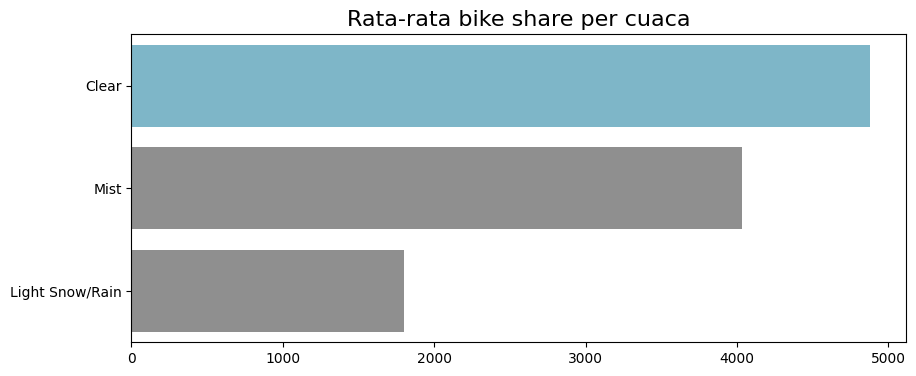

In [48]:
plt.figure(figsize=(10, 4))
sns.barplot(
  data=df_day,
  x="total_user_count",
  y="weather",
  hue="weather",
  palette = ["#72BCD4", "#8f8f8f", "#8f8f8f"],
  errorbar=None
)
plt.title("Rata-rata bike share per cuaca", fontsize=16)
plt.xlabel("")
plt.ylabel("")
plt.show()

### Pertanyaan 3: Bagaimana penggunaan bike sharing pada hari kerja dan perbedannya pada hari libur ?

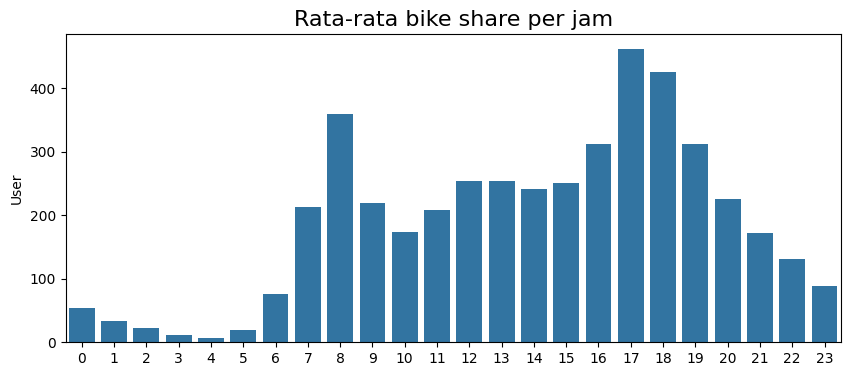

In [49]:
plt.figure(figsize=(10, 4))
sns.barplot(
  data=df_hour,
  x="hour",
  y="total_user_count",
  errorbar=None
)
plt.title("Rata-rata bike share per jam", fontsize=16)
plt.xlabel("")
plt.ylabel("User")
plt.show()

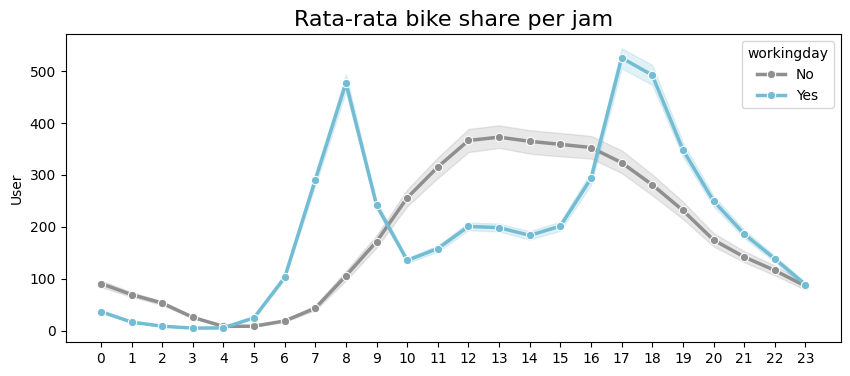

In [50]:
plt.figure(figsize=(10, 4))
sns.lineplot(
  data=df_hour,
  x="hour",
  y="total_user_count",
  hue="workingday",
  palette = ["#8f8f8f", "#72BCD4"],
  linewidth=2.5,
  marker="o"
)
plt.title("Rata-rata bike share per jam", fontsize=16)
plt.xlabel("")
plt.ylabel("User")
plt.xticks(range(24))
plt.show()

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata penggunaan Bike Share setiap harinya sebesar 4,504 kali penggunaan. Total Bike Share yang telah digunakan sepanjang 2011 dan 2012 sebesar 3,292,679 penggunaan, dengan penggunaan yang meningkat sebesar 64,9% dibanding tahun pertama.
  - **Peningkatan Jumlah User yang Terdaftar:** User yang mendaftar pada layanan bike share meningkat sebesar 68,4% dibanding tahun pertama, menunjukkan adanya potensi untuk pertumbuhan user yang mendaftar sebagai member bike share.

- **Conclusion pertanyaan 2:** Penggunaan Bike share lebih diminati saat musim panas dan musim gugur dengan cuaca cerah dibanding musim semi dan musim dingin.
  - **Pola Musim dalam Jumlah Rental:** Pada musim panas dan gugur Bike sharing lebih sering digunakan, namun penggunaan pada musim dingin hingga musim semi relatif rendah dikarenakan cuaca yang relatif dingin kurang mendukung pengguna sepeda untuk mengendarai dengan nyaman.
  - **Cuaca cerah sebagai waktu yang ideal:** Rata-rata penggunaan bike sharing sering terjadi pada cuaca cerah, hal ini dikarenakan pengguna dapat mengendarai sepeda tanpa adanya hambatan dari hujan ataupun salju, sehingga menjadi cuaca yang ideal untuk melakukan rental.

- **Conclusion pertanyaan 3:** Penggunaan Bike share lebih sering digunakan saat pagi hari (Pukul 8) dan sore hari (Pukul 17-18).
  - **Peak Hours dalam Rental:** Penggunaan yang melonjak pada pukul 8 pagi dan pukul 17 hingga 18 sore terjadi karena tingginya permintaan untuk penggunaan bike share sebagai alat transportasi untuk berangkat kerja dan pulang kerja.
  - **Grafik peminjaman yang sangat berbeda:** Aktivitas rental menunjukkan pada hari libur rata-rata rental tidak memiliki peminjaman yang melonjak dikarenakan waktu yang sangat luang, namun peminjaman tersebut perlahan meningkat pagi menuju siang.

**Rekomendasi Action Item:**
- **Promo Khusus Weekend:** Untuk meningkatkan penggunaan rental bike sharing pada akhir pekan, diperlukan promo khusus seperti potongan harga pada akhir pekan ataupun promo khusus untuk meningkatkan jumlah rental saat pagi hari seperti hari kerja dan juga mendukung kehidupan sehat dengan bersepeda di pagi hari.